In [9]:
import os
import pandas as pd
import scanpy as sc
import seaborn as sns
import matplotlib.pyplot as plt

In [10]:
pth = os.path.join('..', '..')
pth_data = os.path.join(pth, 'data')
pth_in = os.path.join(pth_data, 'modeling', 'landscape')
pth_out = os.path.join(pth, 'figures', 'CCCA')

In [11]:
df = pd.read_csv(os.path.join(pth_data, 'summary.csv'), index_col = 0)
src_dict = df.Name.to_dict(); src_dict['3CA'] = 'Malignant'

In [12]:
# load & select cancer data
adata_3ca = sc.read_h5ad(os.path.join(pth_in, 'CCCA.h5ad'))
adata_3ca = adata_3ca[adata_3ca.obs.landscape == 'True'].copy()
adata_3ca.obs['source'] = pd.Categorical(['3CA'] * adata_3ca.n_obs)
adata_3ca

AnnData object with n_obs × n_vars = 8460 × 856
    obs: 'sample', 'cell_type', 'complexity', 'umap1', 'umap2', 'g1s_score', 'g2m_score', 'cell_cycle_phase', 'mp_top_score', 'mp_top', 'mp_assignment', 'ebv', 'celltype', 'Title', 'Category', 'Disease', 'Technology', 'Samples', 'Cells ', 'Name', 'patient', 'cell_subtype', 'source', 'disease', 'p16_status', 'site', 't_stage', 'n_stage', 'gender', 'race', 'age', 'tobacco_use', 'alcohol_use', 'hpv', 'hpv_score', 'treatment', 'procedure', 'sorting', 'cluster', 'malignant', 'sample_id', 'cell_subtype_clusters', 'tnm_stage', 'viral', 'location', 'cancer_type', 'treatment_exposure', 'treatment_response', 'cell_lineage', 'type', 'clusters_by_authors', 'cell_QCpass', 'is_tumor', 'cell_compartment', 'cluster_assignment', 'metastasis', 'sex', 'prior_enzalutamide', 'prior_abiraterone', 'prior_taxane', 'prior_platinum', 'prior_sipuleucel_T', 'purity', 'has_bulk_RNA', 'cancer_cell_state', 'PSA', 'source_region', 'gleason_score', 'ERG_status', 'cores',

In [13]:
# load & select developmental data
adata_dev = sc.read_h5ad(os.path.join(pth_in, 'development.h5ad'))
adata_dev = adata_dev[adata_dev.obs.landscape == 'True'].copy()
adata_dev = adata_dev[~((adata_dev.obs.source == 'GSE162534') &
                        (adata_dev.obs.latent_z < .5))].copy()
adata_dev = adata_dev[~((adata_dev.obs.source == 'GSE229103') &
    (adata_dev[:, 'Pou5f1'].X.toarray() == 0).flatten())].copy()
adata_dev

AnnData object with n_obs × n_vars = 6271 × 856
    obs: 'Stages', 'Clusters', 'Type', 'LineageAnnotations', 'celltype', 'trajectory', 't', 'training', 'validation', 'sample', 'n_genes', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'leiden', 'plates', 'devtime', 'location', 'total_counts_ERCC', 'pct_counts_ERCC', 'doublet_scores', 'CytoTRACE', 'Gut_neuron', 'Sensory', 'Symp', 'enFib', 'ChC', 'Gut_glia', 'NCC', 'Mesenchyme', 'Melanocytes', 'SatGlia', 'SC', 'BCC', 'conflict', 'assignments', 'Hub', 'Hub_leiden', 'total_counts_ribo', 'pct_counts_ribo', 'T+ Sox2+', 'batch', 'percent_mito', 'n_counts', 'bh_pval', 'region', 'tissue', 'adj_stage', 'adj_sample', 'S_score', 'G2M_score', 'phase', 'leiden_R', 'celltype_original', 'orig.ident', 'nCount_RNA', 'nFeature_RNA', 'RNA_snn_res.0.1', 'seurat_clusters', 'age', 'RNA_snn_res.0.5', 'ident', 'velocity_self_transition', 'source', 'weight_celltype', 'weight_source', 'weight', 'latent_z', 'Early', 'Late', 'X_mesen1', 'X

In [14]:
adata = sc.concat((adata_dev, adata_3ca), join = 'inner')
adata

AnnData object with n_obs × n_vars = 14731 × 856
    obs: 'celltype', 'sample', 'location', 'batch', 'nCount_RNA', 'nFeature_RNA', 'age', 'source', 'latent_z', 'Early', 'Late', 'X_mesen1', 'X_mesen2', 'landscape'
    obsm: 'X_mesen', 'X_mod'

In [15]:
# clip early signatures (q = [.05, .95])
for src, sdf in adata.obs.groupby('source', observed = True):
    qq = sdf.Early.quantile([.05, .95])
    adata.obs.loc[sdf.index, 'Early_clip'] = sdf.Early.clip(*qq)

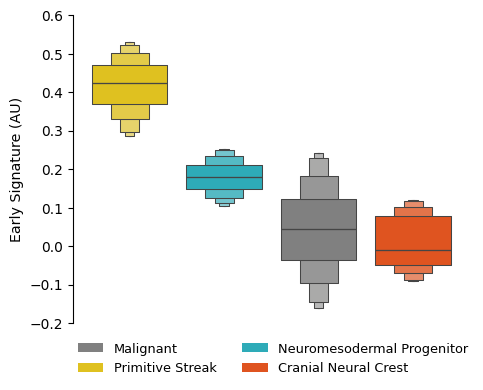

In [16]:
df_plt = adata.obs.copy()
xx, yy = 'source', 'Early_clip'
df_plt[xx] = df_plt[xx].map(src_dict)
ix = (df_plt
      .groupby(xx, observed = True)[yy].mean()
      .sort_values(ascending = False).index)

c = {'Malignant'                  : 'gray',
     'Primitive Streak'           : 'gold',
     'Neuromesodermal Progenitor' : 'tab:cyan',
     'Cranial Neural Crest'       : 'orangered'}

# plot signatures -> dendrogram
fig, ax = plt.subplots(1, 1, figsize = (5, 4))
sns.boxenplot(data = df_plt, x = xx, y = yy,
              order = ix, hue = xx, palette = c,
              showfliers = False, legend = True,
              ax = ax)

ax.set_xticks([])
ax.set_xlabel('')
xlim = ax.get_xlim()
ax.set_xlim(xlim[0] - .1, xlim[1])
ax.set_ylim(-.2, .6)
ax.set_ylabel('Early Signature (AU)', fontsize = 10.25)

leg = ax.legend(
    ncols = 2, fontsize = 9.25, frameon = False,
    bbox_to_anchor = (1.05, -.025))
for h in leg.legend_handles:
    h.set_linewidth(0)
for sp in ('top', 'right', 'bottom'):
    ax.spines[sp].set_visible(False)
    
fn = os.path.join(pth_out, 'dendrogram.pdf')
plt.savefig(fn, bbox_inches = 'tight')